<a href="https://colab.research.google.com/github/dharaniharini2003-op/urban-pulse-nyc-311-analytics/blob/main/Project1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install requests pandas

In [ ]:

import requests
import pandas as pd
import time

url = "https://data.cityofnewyork.us/resource/erm2-nwe9.json"

all_data = []
offset = 0
limit = 1000
target_records = 100000

while offset < target_records:

    params = {
        "$select": "unique_key,created_date,closed_date,agency,complaint_type,descriptor,borough,status,latitude,longitude",
        "$limit": limit,
        "$offset": offset,
        "$order": "created_date DESC"
    }

    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()

    batch = response.json()

    if len(batch) == 0:
        break

    all_data.extend(batch)

    print("Records fetched:", len(all_data))

    offset += len(batch)

    if len(batch) < limit:
        break

    time.sleep(0.2)

df = pd.DataFrame(all_data)

df.to_csv("urban_pulse_raw.csv", index=False)

print("Total records:", len(df))
print(df.head())


Records fetched: 1000
Records fetched: 2000
Records fetched: 3000
Records fetched: 4000
Records fetched: 5000
Records fetched: 6000
Records fetched: 7000
Records fetched: 8000
Records fetched: 9000
Records fetched: 10000
Records fetched: 11000
Records fetched: 12000
Records fetched: 13000
Records fetched: 14000
Records fetched: 15000
Records fetched: 16000
Records fetched: 17000
Records fetched: 18000
Records fetched: 19000
Records fetched: 20000
Records fetched: 21000
Records fetched: 22000
Records fetched: 23000
Records fetched: 24000
Records fetched: 25000
Records fetched: 26000
Records fetched: 27000
Records fetched: 28000
Records fetched: 29000
Records fetched: 30000
Records fetched: 31000
Records fetched: 32000
Records fetched: 33000
Records fetched: 34000
Records fetched: 35000
Records fetched: 36000
Records fetched: 37000
Records fetched: 38000
Records fetched: 39000
Records fetched: 40000
Records fetched: 41000
Records fetched: 42000
Records fetched: 43000
Records fetched: 440

In [ ]:
nyc311_df = pd.DataFrame(all_data)

print("Rows collected:", len(nyc311_df))
print("Columns collected:", len(nyc311_df.columns))

nyc311_df.head()

Rows collected: 100000
Columns collected: 10


,unique_key,created_date,closed_date,agency,complaint_type,descriptor,borough,status,latitude,longitude
0,70919536,2026-10-29T02:38:41.000,2026-10-29T02:38:41.000,DOT,Street Condition,Pothole,MANHATTAN,Closed,40.794755363748415,-73.94234826097029
1,70919535,2026-10-29T02:35:24.000,NaN,DOT,Street Condition,Pothole,MANHATTAN,Open,40.794755363748415,-73.94234826097029
2,70925522,2026-10-29T02:03:51.000,NaN,NYPD,Noise - Street/Sidewalk,Loud Talking,MANHATTAN,In Progress,40.73637716939731,-73.98493484247116
3,70921261,2026-10-29T02:03:14.000,NaN,NYPD,Illegal Parking,Blocked Hydrant,BRONX,In Progress,40.853819743594265,-73.8312830766709
4,70919714,2026-10-29T02:01:47.000,NaN,DEP,Noise,Alarm,MANHATTAN,In Progress,40.74756297125971,-73.99684931958586


In [ ]:
print("Column names:")
print(nyc311_df.columns.tolist())

print("\nData types:")
print(nyc311_df.dtypes)

Column names:
['unique_key', 'created_date', 'closed_date', 'agency', 'complaint_type', 'descriptor', 'borough', 'status', 'latitude', 'longitude']

Data types:
unique_key        object
created_date      object
closed_date       object
agency            object
complaint_type    object
descriptor        object
borough           object
status            object
latitude          object
longitude         object
dtype: object


In [ ]:
csv_file = "nyc311_raw_sample.csv"

nyc311_df.to_csv(csv_file, index=False)

print("Saved file:", csv_file)

from google.colab import files
files.download(csv_file)

Saved file: nyc311_raw_sample.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("Dataset Shape:")
print(nyc311_df.shape)

print("\nMissing Values:")
print(nyc311_df.isnull().sum())

print("\nMissing Percentage:")
print((nyc311_df.isnull().mean() * 100).round(2))

print("\nDuplicate Rows:")
print(nyc311_df.duplicated().sum())

print("\nDuplicate Unique Keys:")
print(nyc311_df["unique_key"].duplicated().sum())

Dataset Shape:
(100000, 10)

Missing Values:
unique_key            0
created_date          0
closed_date       28413
agency                0
complaint_type        0
descriptor            0
borough               0
status                0
latitude           1586
longitude          1586
dtype: int64

Missing Percentage:
unique_key         0.00
created_date       0.00
closed_date       28.41
agency             0.00
complaint_type     0.00
descriptor         0.00
borough            0.00
status             0.00
latitude           1.59
longitude          1.59
dtype: float64

Duplicate Rows:
8

Duplicate Unique Keys:
8


In [ ]:
print("\nComplaint Types:")
print(nyc311_df["complaint_type"].nunique())

print("\nAgencies:")
print(nyc311_df["agency"].nunique())

print("\nBoroughs:")
print(nyc311_df["borough"].value_counts(dropna=False))

print("\nStatuses:")
print(nyc311_df["status"].value_counts(dropna=False))


Complaint Types:
160

Agencies:
14

Boroughs:
borough
BROOKLYN         32810
QUEENS           22675
MANHATTAN        21585
BRONX            19403
STATEN ISLAND     3413
Unspecified        114
Name: count, dtype: int64

Statuses:
status
Closed         69180
Open           18900
In Progress    11659
Assigned         211
Pending           47
Unspecified        3
Name: count, dtype: int64


In [ ]:
# ============================================
# URBAN PULSE - DATA CLEANING & PREPARATION
# ============================================

import pandas as pd
import numpy as np

# Make a copy of the raw dataset
clean_df = nyc311_df.copy()

print("Original dataset shape:", clean_df.shape)


# --------------------------------------------
# 1. CONVERT DATE COLUMNS
# --------------------------------------------

clean_df["created_date"] = pd.to_datetime(
    clean_df["created_date"],
    errors="coerce"
)

clean_df["closed_date"] = pd.to_datetime(
    clean_df["closed_date"],
    errors="coerce"
)


# --------------------------------------------
# 2. CONVERT LATITUDE/LONGITUDE TO NUMERIC
# --------------------------------------------

clean_df["latitude"] = pd.to_numeric(
    clean_df["latitude"],
    errors="coerce"
)

clean_df["longitude"] = pd.to_numeric(
    clean_df["longitude"],
    errors="coerce"
)


# --------------------------------------------
# 3. CLEAN TEXT COLUMNS
# --------------------------------------------

text_columns = [
    "agency",
    "complaint_type",
    "descriptor",
    "borough",
    "status"
]

for col in text_columns:
    if col in clean_df.columns:
        clean_df[col] = (
            clean_df[col]
            .astype("string")
            .str.strip()
        )


# --------------------------------------------
# 4. DUPLICATE CHECK
# --------------------------------------------

duplicate_rows = clean_df.duplicated().sum()
duplicate_keys = clean_df["unique_key"].duplicated().sum()

print("\nDuplicate complete rows:", duplicate_rows)
print("Duplicate unique keys:", duplicate_keys)


# --------------------------------------------
# 5. CREATE IS_CLOSED
# --------------------------------------------

clean_df["is_closed"] = clean_df["closed_date"].notna()


# --------------------------------------------
# 6. CREATE RESOLUTION HOURS
# --------------------------------------------

clean_df["resolution_hours"] = (
    clean_df["closed_date"] -
    clean_df["created_date"]
).dt.total_seconds() / 3600


# --------------------------------------------
# 7. FLAG INVALID RESOLUTION TIMES
# --------------------------------------------

clean_df["invalid_resolution"] = (
    clean_df["resolution_hours"].notna() &
    (clean_df["resolution_hours"] < 0)
)


# --------------------------------------------
# 8. FLAG INVALID DATES
# --------------------------------------------

clean_df["invalid_dates"] = (
    clean_df["created_date"].isna() |
    (
        clean_df["closed_date"].notna() &
        (clean_df["closed_date"] < clean_df["created_date"])
    )
)


# --------------------------------------------
# 9. FLAG INVALID COORDINATES
# --------------------------------------------

clean_df["invalid_coordinates"] = (
    clean_df["latitude"].isna() |
    clean_df["longitude"].isna() |
    ~clean_df["latitude"].between(40, 41.5) |
    ~clean_df["longitude"].between(-75, -73)
)


# --------------------------------------------
# 10. TEMPORAL FEATURES
# --------------------------------------------

clean_df["created_year"] = clean_df["created_date"].dt.year

clean_df["created_month"] = clean_df["created_date"].dt.month

clean_df["created_month_name"] = (
    clean_df["created_date"].dt.month_name()
)

clean_df["created_weekday"] = (
    clean_df["created_date"].dt.day_name()
)

clean_df["created_hour"] = (
    clean_df["created_date"].dt.hour
)


# --------------------------------------------
# 11. DISPLAY CLEANING SUMMARY
# --------------------------------------------

print("\n" + "=" * 50)
print("CLEANING SUMMARY")
print("=" * 50)

print("Rows:", len(clean_df))
print("Columns:", len(clean_df.columns))

print("\nMissing values:")
print(clean_df.isnull().sum())

print("\nClosed records:", clean_df["is_closed"].sum())
print("Open/non-closed records:", (~clean_df["is_closed"]).sum())

print(
    "\nInvalid resolution records:",
    clean_df["invalid_resolution"].sum()
)

print(
    "Invalid date records:",
    clean_df["invalid_dates"].sum()
)

print(
    "Potentially invalid coordinate records:",
    clean_df["invalid_coordinates"].sum()
)

print("\nFirst 5 cleaned records:")
display(clean_df.head())

Original dataset shape: (100000, 10)

Duplicate complete rows: 8
Duplicate unique keys: 8

CLEANING SUMMARY
Rows: 100000
Columns: 20

Missing values:
unique_key                 0
created_date               0
closed_date            28413
agency                     0
complaint_type             0
descriptor                 0
borough                    0
status                     0
latitude                1586
longitude               1586
is_closed                  0
resolution_hours       28413
invalid_resolution         0
invalid_dates              0
invalid_coordinates        0
created_year               0
created_month              0
created_month_name         0
created_weekday            0
created_hour               0
dtype: int64

Closed records: 71587
Open/non-closed records: 28413

Invalid resolution records: 108
Invalid date records: 108
Potentially invalid coordinate records: 1586

First 5 cleaned records:


,unique_key,created_date,closed_date,agency,complaint_type,descriptor,borough,status,latitude,longitude,is_closed,resolution_hours,invalid_resolution,invalid_dates,invalid_coordinates,created_year,created_month,created_month_name,created_weekday,created_hour
0,70919536,2026-10-29 02:38:41,2026-10-29 02:38:41,DOT,Street Condition,Pothole,MANHATTAN,Closed,40.794755,-73.942348,True,0.0,False,False,False,2026,10,October,Thursday,2
1,70919535,2026-10-29 02:35:24,NaT,DOT,Street Condition,Pothole,MANHATTAN,Open,40.794755,-73.942348,False,NaN,False,False,False,2026,10,October,Thursday,2
2,70925522,2026-10-29 02:03:51,NaT,NYPD,Noise - Street/Sidewalk,Loud Talking,MANHATTAN,In Progress,40.736377,-73.984935,False,NaN,False,False,False,2026,10,October,Thursday,2
3,70921261,2026-10-29 02:03:14,NaT,NYPD,Illegal Parking,Blocked Hydrant,BRONX,In Progress,40.853820,-73.831283,False,NaN,False,False,False,2026,10,October,Thursday,2
4,70919714,2026-10-29 02:01:47,NaT,DEP,Noise,Alarm,MANHATTAN,In Progress,40.747563,-73.996849,False,NaN,False,False,False,2026,10,October,Thursday,2


In [ ]:
# ============================================
# SAVE CLEANED URBAN PULSE DATASET
# ============================================

cleaned_file = "nyc311_cleaned.csv"

clean_df.to_csv(cleaned_file, index=False)

print("Cleaned dataset saved successfully!")
print("File:", cleaned_file)
print("Rows:", len(clean_df))
print("Columns:", len(clean_df.columns))

Cleaned dataset saved successfully!
File: nyc311_cleaned.csv
Rows: 100000
Columns: 20


In [ ]:
from google.colab import files

files.download(cleaned_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================
# RESOLUTION TIME STATISTICS
# ============================================

resolution = clean_df.loc[
    (clean_df["resolution_hours"].notna()) &
    (clean_df["resolution_hours"] >= 0),
    "resolution_hours"
]

print("=" * 60)
print("RESOLUTION TIME STATISTICS")
print("=" * 60)

print("Valid resolution records:", len(resolution))

print("\nMean:", round(resolution.mean(), 2), "hours")
print("Median:", round(resolution.median(), 2), "hours")
print("Minimum:", round(resolution.min(), 2), "hours")
print("Maximum:", round(resolution.max(), 2), "hours")
print("Range:", round(resolution.max() - resolution.min(), 2), "hours")

print("\nQuartiles:")
print("Q1:", round(resolution.quantile(0.25), 2))
print("Q2 / Median:", round(resolution.quantile(0.50), 2))
print("Q3:", round(resolution.quantile(0.75), 2))

print("\nVariance:", round(resolution.var(), 2))
print("Standard Deviation:", round(resolution.std(), 2))

print("\nSkewness:", round(resolution.skew(), 2))

RESOLUTION TIME STATISTICS
Valid resolution records: 71479

Mean: 18.51 hours
Median: 2.62 hours
Minimum: 0.0 hours
Maximum: 198.93 hours
Range: 198.93 hours

Quartiles:
Q1: 0.74
Q2 / Median: 2.62
Q3: 19.9

Variance: 1045.49
Standard Deviation: 32.33

Skewness: 2.28


In [ ]:
# ============================================
# IQR OUTLIER ANALYSIS
# ============================================

Q1 = resolution.quantile(0.25)
Q3 = resolution.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("=" * 60)
print("IQR OUTLIER ANALYSIS")
print("=" * 60)

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))

print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))

outlier_mask = (
    (clean_df["resolution_hours"] < lower_bound) |
    (clean_df["resolution_hours"] > upper_bound)
)

outlier_count = outlier_mask.sum()

print("\nPotential outliers:", outlier_count)
print(
    "Percentage of valid resolution records:",
    round((outlier_count / len(resolution)) * 100, 2),
    "%"
)

IQR OUTLIER ANALYSIS
Q1: 0.74
Q3: 19.9
IQR: 19.16
Lower Bound: -27.99
Upper Bound: 48.63

Potential outliers: 10807
Percentage of valid resolution records: 15.12 %


In [ ]:
clean_df["resolution_outlier"] = outlier_mask

In [ ]:
# ============================================
# TOP 10 COMPLAINT TYPES
# ============================================

top_complaints = (
    clean_df["complaint_type"]
    .value_counts()
    .head(10)
)

print("TOP 10 COMPLAINT TYPES")
print("=" * 50)

print(top_complaints)

TOP 10 COMPLAINT TYPES
complaint_type
Illegal Parking            17113
HEAT/HOT WATER             10798
Noise - Residential         8906
Blocked Driveway            4902
Noise - Street/Sidewalk     4198
UNSANITARY CONDITION        4136
Noise                       2169
PLUMBING                    2113
Street Condition            2060
PAINT/PLASTER               1947
Name: count, dtype: Int64


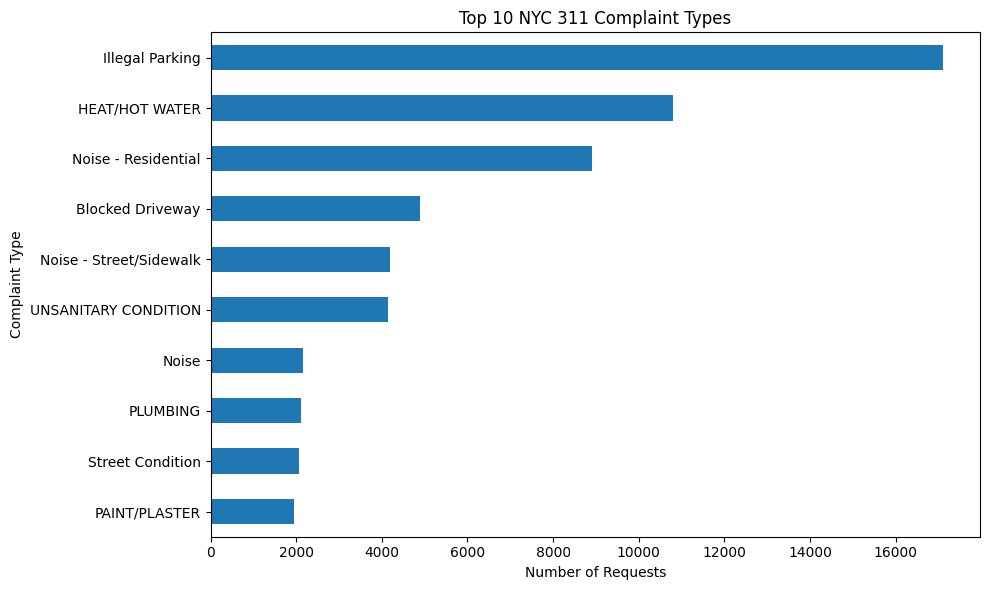

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

top_complaints.sort_values().plot(kind="barh")

plt.title("Top 10 NYC 311 Complaint Types")
plt.xlabel("Number of Requests")
plt.ylabel("Complaint Type")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# AGENCY WORKLOAD
# ============================================

agency_counts = (
    clean_df["agency"]
    .value_counts()
)

print("AGENCY WORKLOAD")
print("=" * 50)

print(agency_counts)

AGENCY WORKLOAD
agency
NYPD     42459
HPD      26453
DSNY      7700
DOT       6062
DEP       5500
DOB       2755
DPR       2495
DHS       2429
DOHMH     2222
TLC       1009
DCWP       585
EDC        188
OOS        134
OTI          9
Name: count, dtype: Int64


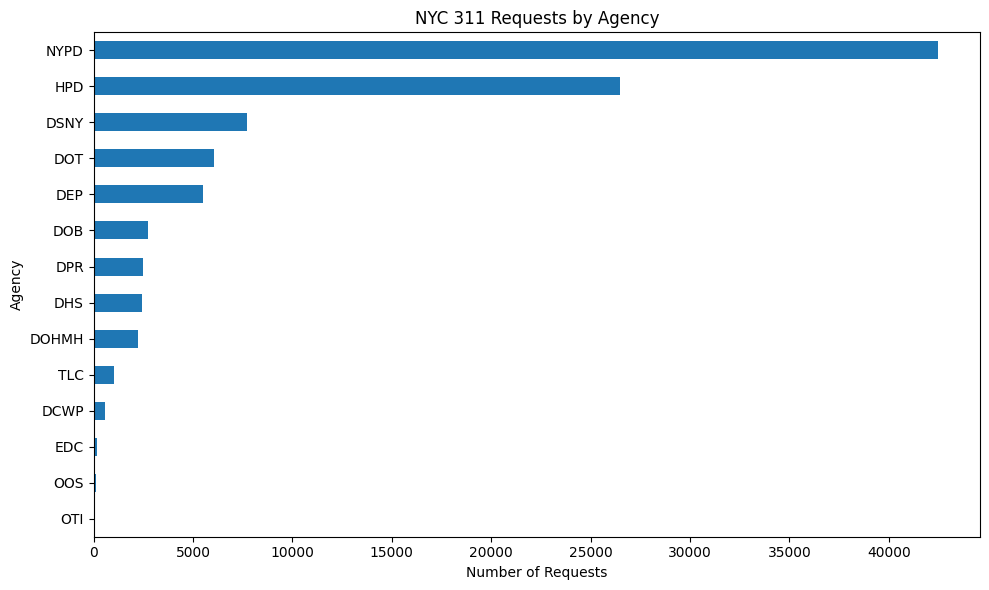

In [ ]:
plt.figure(figsize=(10, 6))

agency_counts.sort_values().plot(kind="barh")

plt.title("NYC 311 Requests by Agency")
plt.xlabel("Number of Requests")
plt.ylabel("Agency")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# REQUESTS BY BOROUGH
# ============================================

borough_counts = (
    clean_df["borough"]
    .value_counts()
)

print("REQUESTS BY BOROUGH")
print("=" * 50)

print(borough_counts)

REQUESTS BY BOROUGH
borough
BROOKLYN         32810
QUEENS           22675
MANHATTAN        21585
BRONX            19403
STATEN ISLAND     3413
Unspecified        114
Name: count, dtype: Int64


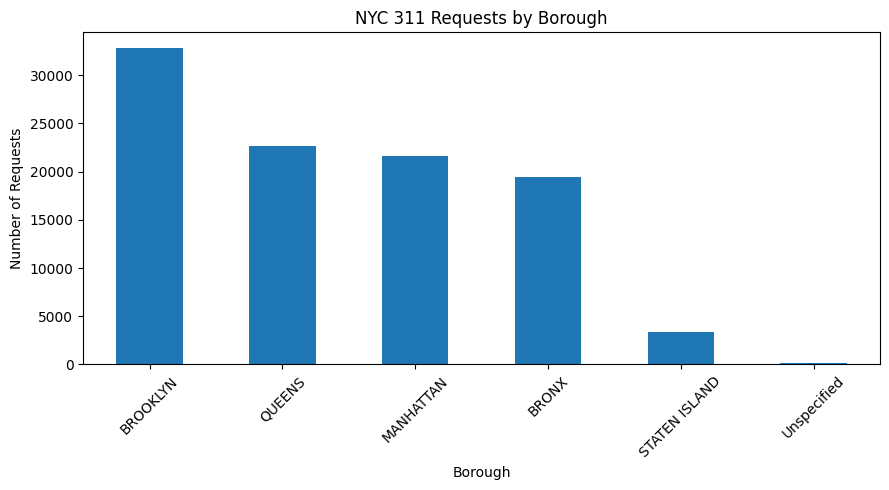

In [ ]:
plt.figure(figsize=(9, 5))

borough_counts.plot(kind="bar")

plt.title("NYC 311 Requests by Borough")
plt.xlabel("Borough")
plt.ylabel("Number of Requests")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# MONTHLY REQUEST TREND
# ============================================

monthly_requests = (
    clean_df
    .set_index("created_date")
    .resample("ME")
    .size()
)

print("MONTHLY REQUEST TREND")
print("=" * 50)

print(monthly_requests)

MONTHLY REQUEST TREND
created_date
2026-10-31    100000
Freq: ME, dtype: int64


/usr/local/lib/python3.13/dist-packages/pandas/plotting/_matplotlib/core.py:1567: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(left, right)


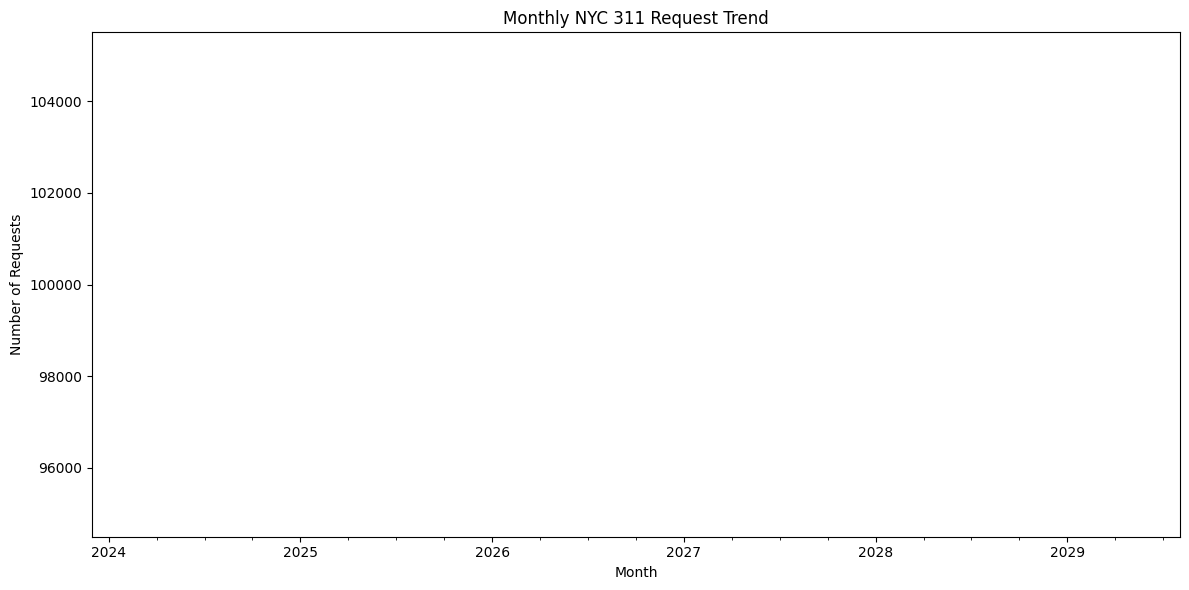

In [ ]:
plt.figure(figsize=(12, 6))

monthly_requests.plot()

plt.title("Monthly NYC 311 Request Trend")
plt.xlabel("Month")
plt.ylabel("Number of Requests")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# REQUESTS BY WEEKDAY
# ============================================

weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_counts = (
    clean_df["created_weekday"]
    .value_counts()
    .reindex(weekday_order)
)

print("REQUESTS BY WEEKDAY")
print("=" * 50)

print(weekday_counts)

REQUESTS BY WEEKDAY
created_weekday
Monday       12496
Tuesday      18444
Wednesday    23797
Thursday     11636
Friday       12313
Saturday     10836
Sunday       10478
Name: count, dtype: int64


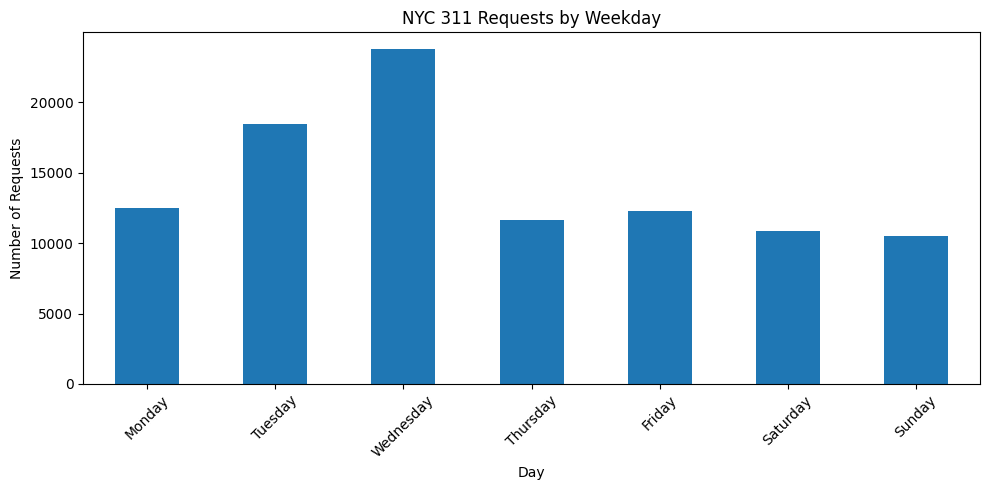

In [ ]:
plt.figure(figsize=(10, 5))

weekday_counts.plot(kind="bar")

plt.title("NYC 311 Requests by Weekday")
plt.xlabel("Day")
plt.ylabel("Number of Requests")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# REQUESTS BY HOUR
# ============================================

hour_counts = (
    clean_df["created_hour"]
    .value_counts()
    .sort_index()
)

print("REQUESTS BY HOUR")
print("=" * 50)

print(hour_counts)

REQUESTS BY HOUR
created_hour
0     3162
1     2359
2     1678
3     1111
4     1164
5     1445
6     2379
7     3967
8     5386
9     5807
10    6068
11    5641
12    5609
13    5671
14    5463
15    5536
16    5320
17    4972
18    4516
19    4366
20    4510
21    4765
22    4933
23    4172
Name: count, dtype: int64


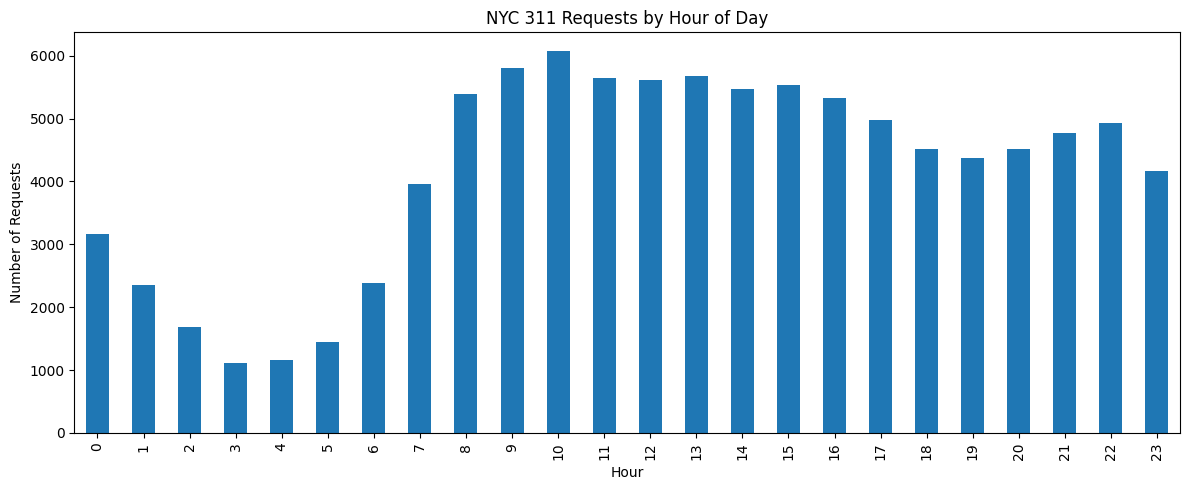

In [ ]:
plt.figure(figsize=(12, 5))

hour_counts.plot(kind="bar")

plt.title("NYC 311 Requests by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Number of Requests")

plt.xticks(range(24))

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# STATUS DISTRIBUTION
# ============================================

status_counts = clean_df["status"].value_counts()

print("STATUS DISTRIBUTION")
print("=" * 50)

print(status_counts)

STATUS DISTRIBUTION
status
Closed         69180
Open           18900
In Progress    11659
Assigned         211
Pending           47
Unspecified        3
Name: count, dtype: Int64


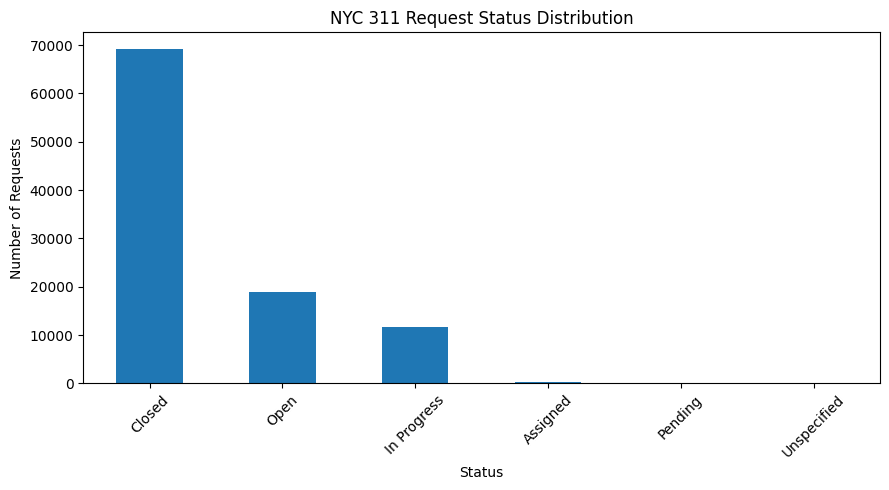

In [ ]:
plt.figure(figsize=(9, 5))

status_counts.plot(kind="bar")

plt.title("NYC 311 Request Status Distribution")
plt.xlabel("Status")
plt.ylabel("Number of Requests")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# CLOSURE RATE
# ============================================

total_requests = clean_df["unique_key"].nunique()

closed_requests = clean_df["is_closed"].sum()

closure_rate = (
    closed_requests / len(clean_df)
) * 100

print("Total requests:", total_requests)
print("Closed requests:", closed_requests)
print("Recorded closure rate:", round(closure_rate, 2), "%")
print("Open/non-closed:", len(clean_df) - closed_requests)

Total requests: 99992
Closed requests: 71587
Recorded closure rate: 71.59 %
Open/non-closed: 28413


In [ ]:
# ============================================
# RESOLUTION > 72 HOURS
# ============================================

valid_resolution_df = clean_df[
    (clean_df["resolution_hours"].notna()) &
    (clean_df["resolution_hours"] >= 0)
].copy()

over_72_hours = (
    valid_resolution_df["resolution_hours"] > 72
).sum()

over_72_percentage = (
    over_72_hours / len(valid_resolution_df)
) * 100

print("Valid resolution records:", len(valid_resolution_df))
print("Resolved in >72 hours:", over_72_hours)
print(
    "Percentage >72 hours:",
    round(over_72_percentage, 2),
    "%"
)

Valid resolution records: 71479
Resolved in >72 hours: 6820
Percentage >72 hours: 9.54 %


In [ ]:
# ============================================
# MEDIAN RESOLUTION BY COMPLAINT TYPE
# ============================================

median_by_complaint = (
    valid_resolution_df
    .groupby("complaint_type")["resolution_hours"]
    .median()
    .sort_values(ascending=False)
)

print("MEDIAN RESOLUTION BY COMPLAINT TYPE")
print("=" * 60)

print(median_by_complaint.head(20))

MEDIAN RESOLUTION BY COMPLAINT TYPE
complaint_type
Curb Condition                    168.139306
OUTSIDE BUILDING                  143.850833
Highway Sign - Damaged            143.849444
Standing Water                    126.441389
Cooling Tower                     118.755278
Drinking Water                    114.292222
Unsanitary Animal Pvt Property    105.583333
Food Establishment                105.336944
ELEVATOR                          102.720000
Public Toilet                      99.723611
Unleashed Dog                      99.542500
Indoor Sewage                      95.132639
Root/Sewer/Sidewalk Condition      95.118889
Ferry Inquiry                      94.926389
Illegal Animal Kept as Pet         92.088333
APPLIANCE                          90.882500
UNSANITARY CONDITION               84.683333
DOOR/WINDOW                        84.431111
WATER LEAK                         81.789583
Rodent                             80.416528
Name: resolution_hours, dtype: float64


In [ ]:
# ============================================
# MEDIAN RESOLUTION BY AGENCY
# ============================================

median_by_agency = (
    valid_resolution_df
    .groupby("agency")["resolution_hours"]
    .median()
    .sort_values(ascending=False)
)

print("MEDIAN RESOLUTION BY AGENCY")
print("=" * 60)

print(median_by_agency)

MEDIAN RESOLUTION BY AGENCY
agency
TLC      65.038889
HPD      58.512222
DOHMH    50.504861
DSNY     28.900000
OOS      27.698750
DPR      27.065000
DCWP     23.700833
DOT      18.338611
DEP      17.317500
DHS       4.135972
NYPD      1.247500
DOB       0.000000
Name: resolution_hours, dtype: float64


In [ ]:
# ============================================
# HIGH-VOLUME + LONG-RESOLUTION CATEGORIES
# ============================================

category_analysis = (
    valid_resolution_df
    .groupby("complaint_type")
    .agg(
        request_count=("unique_key", "nunique"),
        median_resolution_hours=("resolution_hours", "median")
    )
    .sort_values(
        "request_count",
        ascending=False
    )
)

print(category_analysis.head(20))

                               request_count  median_resolution_hours
complaint_type                                                       
Illegal Parking                        16958                 1.325556
Noise - Residential                     8808                 1.190556
HEAT/HOT WATER                          8352                55.989722
Blocked Driveway                        4858                 1.449722
Noise - Street/Sidewalk                 4145                 0.966944
Abandoned Vehicle                       1804                 2.070278
Noise - Commercial                      1656                 0.987778
Noise                                   1471                38.040278
Street Condition                        1382                21.758194
Water Maintenance                       1288                 1.770694
Encampment                              1217                 3.108611
Dirty Condition                         1195                44.102639
Noise - Vehicle     

In [ ]:
volume_median = category_analysis["request_count"].median()
resolution_median = category_analysis["median_resolution_hours"].median()

high_volume_long_resolution = category_analysis[
    (category_analysis["request_count"] > volume_median) &
    (category_analysis["median_resolution_hours"] > resolution_median)
]

print("\nHIGH-VOLUME + LONG-RESOLUTION CATEGORIES")
print("=" * 60)

print(high_volume_long_resolution.sort_values(
    "median_resolution_hours",
    ascending=False
))


HIGH-VOLUME + LONG-RESOLUTION CATEGORIES
                                request_count  median_resolution_hours
complaint_type                                                        
APPLIANCE                                 113                90.882500
UNSANITARY CONDITION                      568                84.683333
DOOR/WINDOW                               258                84.431111
WATER LEAK                                182                81.789583
Rodent                                    156                80.416528
FLOORING/STAIRS                           135                80.202222
PAINT/PLASTER                             420                75.752778
SAFETY                                    104                71.584028
Sidewalk Condition                        238                66.365278
Lost Property                             120                65.367222
GENERAL                                   237                60.116111
ELECTRIC                           

In [ ]:
# ============================================
# URBAN PULSE - ANALYTICAL SUMMARY
# ============================================

summary = {
    "Total Rows": len(clean_df),
    "Distinct Requests": clean_df["unique_key"].nunique(),
    "Complaint Types": clean_df["complaint_type"].nunique(),
    "Agencies": clean_df["agency"].nunique(),
    "Closed Requests": clean_df["is_closed"].sum(),
    "Non-Closed Requests": (~clean_df["is_closed"]).sum(),
    "Closure Rate (%)": round(
        clean_df["is_closed"].mean() * 100, 2
    ),
    "Valid Resolution Records": len(resolution),
    "Mean Resolution (hours)": round(resolution.mean(), 2),
    "Median Resolution (hours)": round(resolution.median(), 2),
    "Q1 Resolution (hours)": round(resolution.quantile(0.25), 2),
    "Q3 Resolution (hours)": round(resolution.quantile(0.75), 2),
    "IQR (hours)": round(
        resolution.quantile(0.75) -
        resolution.quantile(0.25), 2
    ),
    "Std Deviation (hours)": round(resolution.std(), 2),
    "Skewness": round(resolution.skew(), 2),
    "Potential Outliers": int(clean_df["resolution_outlier"].sum()),
    "Over 72 Hours (%)": round(
        (resolution > 72).mean() * 100, 2
    )
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=["Metric", "Value"]
)

display(summary_df)

,Metric,Value
0,Total Rows,100000.00
1,Distinct Requests,99992.00
2,Complaint Types,160.00
3,Agencies,14.00
4,Closed Requests,71587.00
5,Non-Closed Requests,28413.00
6,Closure Rate (%),71.59
7,Valid Resolution Records,71479.00
8,Mean Resolution (hours),18.51
9,Median Resolution (hours),2.62


In [ ]:
# ============================================
# GEOGRAPHIC ANALYSIS
# ============================================

geo_df = clean_df[
    ~clean_df["invalid_coordinates"]
].copy()

print("Records with usable coordinates:", len(geo_df))

print("\nRequests by Borough:")
print(
    geo_df["borough"]
    .value_counts()
)

Records with usable coordinates: 98414

Requests by Borough:
borough
BROOKLYN         32449
QUEENS           22141
MANHATTAN        21322
BRONX            19161
STATEN ISLAND     3336
Unspecified          5
Name: count, dtype: Int64


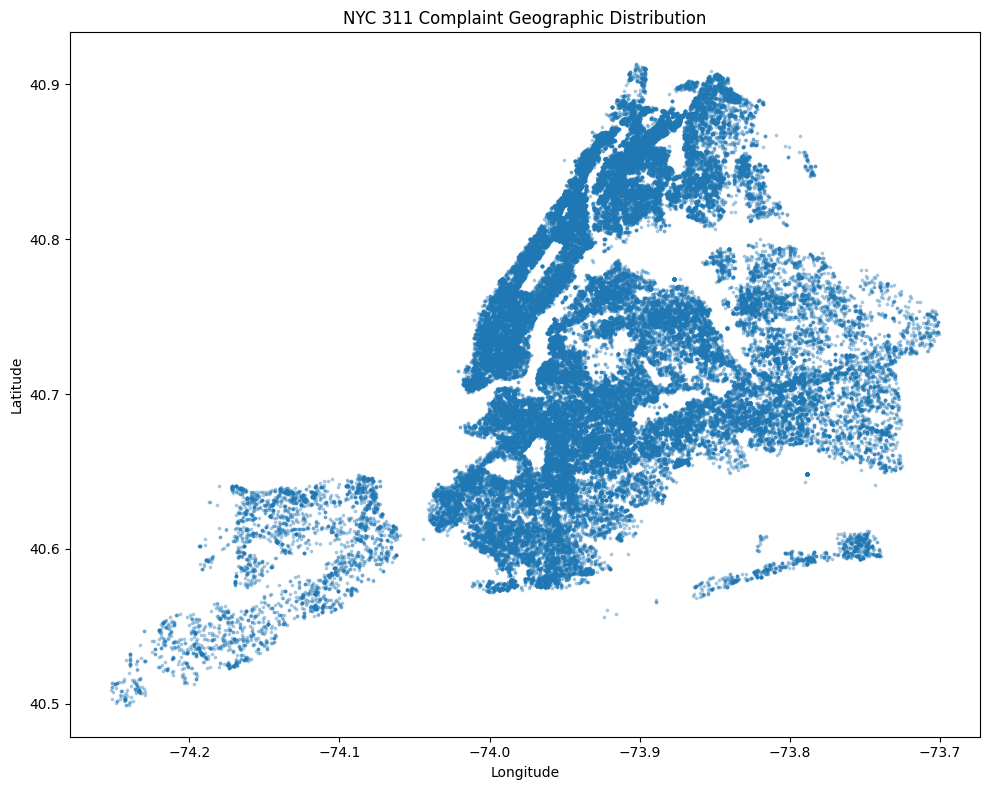

In [ ]:
plt.figure(figsize=(10, 8))

plt.scatter(
    geo_df["longitude"],
    geo_df["latitude"],
    s=3,
    alpha=0.3
)

plt.title("NYC 311 Complaint Geographic Distribution")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# CLOSURE RATE BY AGENCY
# ============================================

agency_closure = (
    clean_df
    .groupby("agency")
    .agg(
        total_requests=("unique_key", "nunique"),
        closed_requests=("is_closed", "sum")
    )
)

agency_closure["closure_rate_percent"] = (
    agency_closure["closed_requests"] /
    agency_closure["total_requests"] * 100
)

agency_closure = agency_closure.sort_values(
    "closure_rate_percent",
    ascending=False
)

display(agency_closure)

,total_requests,closed_requests,closure_rate_percent
agency,,,
DOB,2755,2755,100.000000
NYPD,42457,42053,99.048449
DHS,2429,2318,95.430218
DSNY,7699,5583,72.515911
DEP,5500,3579,65.072727
DOT,6062,2766,45.628505
HPD,26448,11198,42.339685
DCWP,585,203,34.700855
DOHMH,2222,504,22.682268


In [ ]:
# ============================================
# URBAN PULSE - GEOGRAPHIC ANALYSIS
# ============================================

geo_df = clean_df[
    ~clean_df["invalid_coordinates"]
].copy()

print("Total records:", len(clean_df))
print("Records with usable coordinates:", len(geo_df))
print("Records with flagged coordinates:",
      clean_df["invalid_coordinates"].sum())

print("\nRequests by Borough:")
print(
    geo_df["borough"].value_counts()
)

Total records: 100000
Records with usable coordinates: 98414
Records with flagged coordinates: 1586

Requests by Borough:
borough
BROOKLYN         32449
QUEENS           22141
MANHATTAN        21322
BRONX            19161
STATEN ISLAND     3336
Unspecified          5
Name: count, dtype: Int64


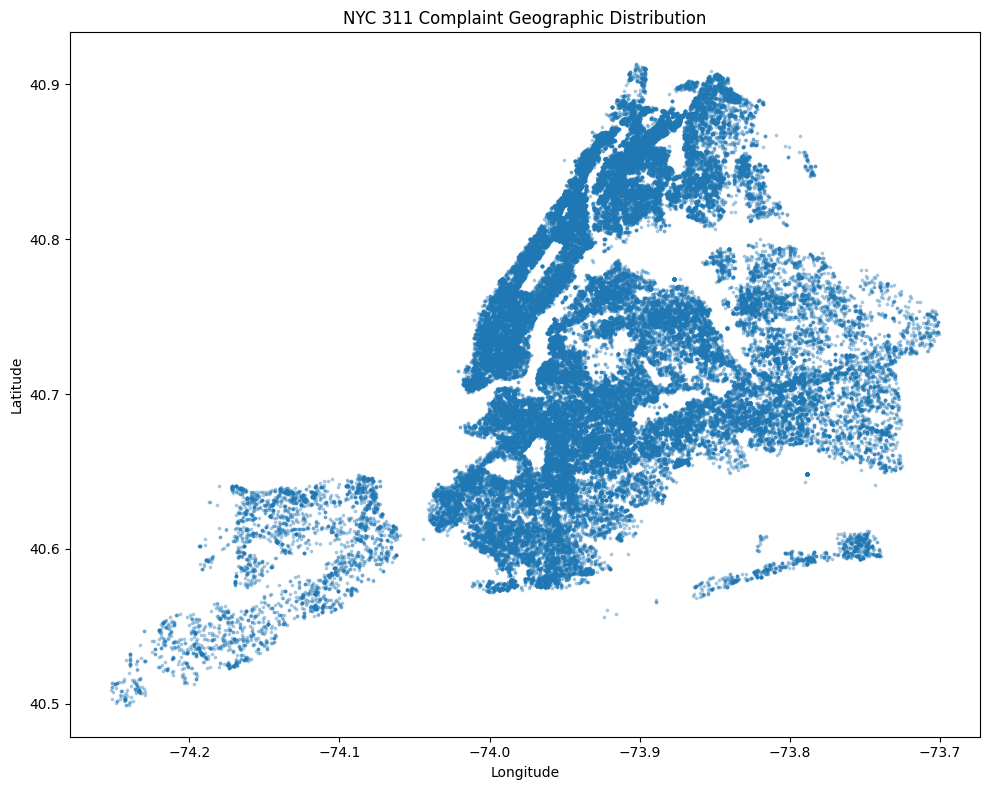

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

plt.scatter(
    geo_df["longitude"],
    geo_df["latitude"],
    s=3,
    alpha=0.3
)

plt.title("NYC 311 Complaint Geographic Distribution")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.tight_layout()
plt.show()

In [ ]:
borough_complaint = pd.crosstab(
    clean_df["borough"],
    clean_df["complaint_type"]
)

print("Borough × Complaint Type:")
display(borough_complaint)

Borough × Complaint Type:


complaint_type,AHV Inspection Unit,APPLIANCE,Abandoned Bike,Abandoned Vehicle,Air Quality,Animal Facility - No Permit,Animal in a Park,Animal-Abuse,Asbestos,BEST/Site Safety,...,Vendor Enforcement,Violation of Park Rules,WATER LEAK,Waste Water Treatment Plant,Water Conservation,Water Maintenance,Water Quality,Wayfinding,Wood Pile Remaining,X-Ray Machine/Equipment
borough,,,,,,,,,,,,,,,,,,,,,
BRONX,1,298,6,254,12,0,12,58,2,2,...,71,10,381,0,12,485,10,0,0,0
BROOKLYN,7,262,25,594,79,0,61,116,6,8,...,113,26,409,5,16,568,9,0,6,0
MANHATTAN,3,167,17,72,133,0,43,66,7,6,...,348,40,251,6,6,204,13,1,0,2
QUEENS,0,90,9,747,51,1,24,62,4,6,...,145,15,146,20,17,403,12,0,4,0
STATEN ISLAND,0,12,0,160,8,0,2,30,1,0,...,4,3,10,0,10,160,4,0,2,0
Unspecified,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
top_complaint_by_borough = (
    clean_df
    .groupby(["borough", "complaint_type"])
    .size()
    .reset_index(name="request_count")
    .sort_values(
        ["borough", "request_count"],
        ascending=[True, False]
    )
)

top_complaint_by_borough = (
    top_complaint_by_borough
    .groupby("borough")
    .head(1)
)

display(top_complaint_by_borough)

,borough,complaint_type,request_count
50,BRONX,HEAT/HOT WATER,3201
192,BROOKLYN,Illegal Parking,7323
322,MANHATTAN,HEAT/HOT WATER,2793
472,QUEENS,Illegal Parking,4937
600,STATEN ISLAND,Illegal Parking,418
669,Unspecified,For Hire Vehicle Complaint,20


In [ ]:
# ============================================
# URBAN PULSE - 15 ANALYST TASK CHECKLIST
# ============================================

tasks = {
    1: "Total distinct request volume",
    2: "Top 10 complaint categories",
    3: "Agency workload distribution",
    4: "Request volume by borough",
    5: "Monthly request trend",
    6: "Demand by weekday and hour",
    7: "Request status distribution",
    8: "Resolution-time descriptive statistics",
    9: "Median resolution by complaint category",
    10: "Median resolution by agency",
    11: "IQR-based outlier investigation",
    12: "Resolution-time skewness",
    13: "Geographic complaint concentration",
    14: "Recorded closure-rate comparison",
    15: "High-volume + long-resolution categories"
}

for number, task in tasks.items():
    print(f"{number}. {task} - COMPLETED")

1. Total distinct request volume - COMPLETED
2. Top 10 complaint categories - COMPLETED
3. Agency workload distribution - COMPLETED
4. Request volume by borough - COMPLETED
5. Monthly request trend - COMPLETED
6. Demand by weekday and hour - COMPLETED
7. Request status distribution - COMPLETED
8. Resolution-time descriptive statistics - COMPLETED
9. Median resolution by complaint category - COMPLETED
10. Median resolution by agency - COMPLETED
11. IQR-based outlier investigation - COMPLETED
12. Resolution-time skewness - COMPLETED
13. Geographic complaint concentration - COMPLETED
14. Recorded closure-rate comparison - COMPLETED
15. High-volume + long-resolution categories - COMPLETED


In [ ]:
# ============================================
# URBAN PULSE - DATA DICTIONARY
# ============================================

data_dictionary = pd.DataFrame({
    "field_name": [
        "unique_key",
        "created_date",
        "closed_date",
        "agency",
        "complaint_type",
        "descriptor",
        "borough",
        "status",
        "latitude",
        "longitude",
        "is_closed",
        "resolution_hours",
        "invalid_resolution",
        "invalid_dates",
        "invalid_coordinates",
        "created_year",
        "created_month",
        "created_month_name",
        "created_weekday",
        "created_hour"
    ],

    "meaning": [
        "Unique NYC 311 service request identifier",
        "Date and time when request was created",
        "Date and time when request was closed",
        "Agency responsible for the request",
        "Category of complaint",
        "Detailed complaint description",
        "NYC borough",
        "Current recorded request status",
        "Latitude of request",
        "Longitude of request",
        "Indicates whether a closure date is recorded",
        "Elapsed time between creation and closure in hours",
        "Flag for negative resolution duration",
        "Flag for invalid date chronology",
        "Flag for potentially invalid coordinates",
        "Year extracted from created_date",
        "Month number extracted from created_date",
        "Month name extracted from created_date",
        "Weekday extracted from created_date",
        "Hour extracted from created_date"
    ],

    "data_type": [
        "string",
        "datetime",
        "datetime",
        "string",
        "string",
        "string",
        "string",
        "string",
        "numeric",
        "numeric",
        "boolean",
        "numeric",
        "boolean",
        "boolean",
        "boolean",
        "integer",
        "integer",
        "string",
        "string",
        "integer"
    ]
})

display(data_dictionary)

,field_name,meaning,data_type
0,unique_key,Unique NYC 311 service request identifier,string
1,created_date,Date and time when request was created,datetime
2,closed_date,Date and time when request was closed,datetime
3,agency,Agency responsible for the request,string
4,complaint_type,Category of complaint,string
5,descriptor,Detailed complaint description,string
6,borough,NYC borough,string
7,status,Current recorded request status,string
8,latitude,Latitude of request,numeric
9,longitude,Longitude of request,numeric


In [ ]:
data_dictionary.to_csv(
    "urbanpulse_data_dictionary.csv",
    index=False
)

print("Data dictionary saved.")

Data dictionary saved.


In [ ]:
# ============================================
# URBAN PULSE - VALIDATION LOG
# ============================================

validation_log = pd.DataFrame({
    "check": [
        "Raw row count",
        "Cleaned row count",
        "Raw columns",
        "Cleaned columns",
        "Duplicate complete rows",
        "Duplicate unique keys",
        "Missing closed dates",
        "Missing latitude",
        "Missing longitude",
        "Invalid dates",
        "Invalid resolution",
        "Potentially invalid coordinates"
    ],

    "result": [
        len(nyc311_df),
        len(clean_df),
        len(nyc311_df.columns),
        len(clean_df.columns),
        nyc311_df.duplicated().sum(),
        nyc311_df["unique_key"].duplicated().sum(),
        clean_df["closed_date"].isna().sum(),
        clean_df["latitude"].isna().sum(),
        clean_df["longitude"].isna().sum(),
        clean_df["invalid_dates"].sum(),
        clean_df["invalid_resolution"].sum(),
        clean_df["invalid_coordinates"].sum()
    ]
})

display(validation_log)

,check,result
0,Raw row count,100000
1,Cleaned row count,100000
2,Raw columns,10
3,Cleaned columns,21
4,Duplicate complete rows,8
5,Duplicate unique keys,8
6,Missing closed dates,28413
7,Missing latitude,1586
8,Missing longitude,1586
9,Invalid dates,108


In [ ]:
clean_df.to_csv(
    "nyc311_cleaned.csv",
    index=False
)

print("Final cleaned dataset saved.")
print("Rows:", len(clean_df))
print("Columns:", len(clean_df.columns))

Final cleaned dataset saved.
Rows: 100000
Columns: 21


In [ ]:
nyc311_df.to_csv("nyc311_cleaned.csv", index=False)

In [ ]:
print(nyc311_df.columns.tolist())

['unique_key', 'created_date', 'closed_date', 'agency', 'complaint_type', 'descriptor', 'borough', 'status', 'latitude', 'longitude']


In [ ]:
from google.colab import files

files.download("nyc311_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

print("File exists:", os.path.exists("nyc311_cleaned.csv"))
print("File size:", os.path.getsize("nyc311_cleaned.csv"), "bytes")

File exists: True
File size: 14060736 bytes


In [ ]:
!pip install sqlalchemy pymysql

In [ ]:
import os
from getpass import getpass

password = getpass("Enter MySQL password: ")

os.environ["DB_PASSWORD"] = password

print("Password stored successfully!")

Enter MySQL password: ··········
Password stored successfully!


In [ ]:
import os

os.environ["DB_HOST"] = "localhost"
os.environ["DB_USER"] = "root"
os.environ["DB_NAME"] = "urbanpulse_nyc"
os.environ["DB_PORT"] = "3306"

print("Database configuration completed!")

Database configuration completed!


In [ ]:
print("Password available:", "DB_PASSWORD" in os.environ)

Password available: True


In [ ]:
required_variables = [
    "DB_HOST",
    "DB_USER",
    "DB_PASSWORD",
    "DB_NAME",
    "DB_PORT"
]

for variable in required_variables:
    print(variable, ":", "Available" if variable in os.environ else "Missing")

DB_HOST : Available
DB_USER : Available
DB_PASSWORD : Available
DB_NAME : Available
DB_PORT : Available


In [ ]:
print("DB_HOST:", os.environ["DB_HOST"])
print("DB_PORT:", os.environ["DB_PORT"])
print("DB_NAME:", os.environ["DB_NAME"])

DB_HOST: localhost
DB_PORT: 3306
DB_NAME: urbanpulse_nyc


In [ ]:
print("Dataset shape:", nyc311_df.shape)
print("Column names:")
print(nyc311_df.columns.tolist())

nyc311_df.head()

Dataset shape: (100000, 10)
Column names:
['unique_key', 'created_date', 'closed_date', 'agency', 'complaint_type', 'descriptor', 'borough', 'status', 'latitude', 'longitude']


,unique_key,created_date,closed_date,agency,complaint_type,descriptor,borough,status,latitude,longitude
0,70919536,2026-10-29T02:38:41.000,2026-10-29T02:38:41.000,DOT,Street Condition,Pothole,MANHATTAN,Closed,40.794755363748415,-73.94234826097029
1,70919535,2026-10-29T02:35:24.000,NaN,DOT,Street Condition,Pothole,MANHATTAN,Open,40.794755363748415,-73.94234826097029
2,70925522,2026-10-29T02:03:51.000,NaN,NYPD,Noise - Street/Sidewalk,Loud Talking,MANHATTAN,In Progress,40.73637716939731,-73.98493484247116
3,70921261,2026-10-29T02:03:14.000,NaN,NYPD,Illegal Parking,Blocked Hydrant,BRONX,In Progress,40.853819743594265,-73.8312830766709
4,70919714,2026-10-29T02:01:47.000,NaN,DEP,Noise,Alarm,MANHATTAN,In Progress,40.74756297125971,-73.99684931958586


In [ ]:
import pandas as pd

# Convert date columns into datetime format
nyc311_df['created_date'] = pd.to_datetime(
    nyc311_df['created_date'], errors='coerce'
)

nyc311_df['closed_date'] = pd.to_datetime(
    nyc311_df['closed_date'], errors='coerce'
)

# Convert request ID into numeric format
nyc311_df['unique_key'] = pd.to_numeric(
    nyc311_df['unique_key'], errors='coerce'
).astype('Int64')

# Check duplicate request IDs
print("Duplicate request IDs:",
      nyc311_df['unique_key'].duplicated().sum())

# Check missing values
print("\nMissing values:")
print(nyc311_df.isnull().sum())

# Display updated data types
print("\nColumn data types:")
print(nyc311_df.dtypes)

Duplicate request IDs: 8

Missing values:
unique_key            0
created_date          0
closed_date       28413
agency                0
complaint_type        0
descriptor            0
borough               0
status                0
latitude           1586
longitude          1586
dtype: int64

Column data types:
unique_key                 Int64
created_date      datetime64[ns]
closed_date       datetime64[ns]
agency                    object
complaint_type            object
descriptor                object
borough                   object
status                    object
latitude                  object
longitude                 object
dtype: object


In [ ]:
# Display duplicate request IDs
duplicates = nyc311_df[
    nyc311_df['unique_key'].duplicated(keep=False)
].sort_values('unique_key')

print("Duplicate records:", len(duplicates))

display(duplicates)

Duplicate records: 16


,unique_key,created_date,closed_date,agency,complaint_type,descriptor,borough,status,latitude,longitude
70000,70850209,2026-10-22 23:40:52,2026-10-23 14:18:43,DSNY,Dirty Condition,Trash,QUEENS,Closed,40.74272272897521,-73.9148403589507
69999,70850209,2026-10-22 23:40:52,2026-10-23 14:18:43,DSNY,Dirty Condition,Trash,QUEENS,Closed,40.74272272897521,-73.9148403589507
63006,70860326,2026-10-23 14:31:55,NaT,HPD,GENERAL,CABINET,BRONX,Open,40.833301818888344,-73.91885847128074
62999,70860326,2026-10-23 14:31:55,NaT,HPD,GENERAL,CABINET,BRONX,Open,40.833301818888344,-73.91885847128074
61999,70867736,2026-10-23 16:11:30,2026-10-23 21:42:15,NYPD,Illegal Parking,Blocked Sidewalk,BROOKLYN,Closed,40.59314810767946,-73.95832571601332
62000,70867736,2026-10-23 16:11:30,2026-10-23 21:42:15,NYPD,Illegal Parking,Blocked Sidewalk,BROOKLYN,Closed,40.59314810767946,-73.95832571601332
65999,70868218,2026-10-23 10:09:54,NaT,HPD,PLUMBING,WATER SUPPLY,BRONX,Open,40.86538376297527,-73.8882111536868
66001,70868218,2026-10-23 10:09:54,NaT,HPD,PLUMBING,WATER SUPPLY,BRONX,Open,40.86538376297527,-73.8882111536868
69000,70868515,2026-10-23 02:09:45,NaT,HPD,GENERAL,CABINET,BROOKLYN,Open,40.6705042651914,-73.92968364944787
68999,70868515,2026-10-23 02:09:45,NaT,HPD,GENERAL,CABINET,BROOKLYN,Open,40.6705042651914,-73.92968364944787


In [ ]:
# Convert geographical coordinates to numeric
nyc311_df['latitude'] = pd.to_numeric(
    nyc311_df['latitude'], errors='coerce'
)

nyc311_df['longitude'] = pd.to_numeric(
    nyc311_df['longitude'], errors='coerce'
)

# Verify data types
print(nyc311_df[['latitude', 'longitude']].dtypes)

latitude     float64
longitude    float64
dtype: object


In [ ]:
duplicates = nyc311_df[
    nyc311_df['unique_key'].duplicated(keep=False)
].sort_values('unique_key')

print("Number of duplicate rows:", len(duplicates))

display(duplicates)

Number of duplicate rows: 16


,unique_key,created_date,closed_date,agency,complaint_type,descriptor,borough,status,latitude,longitude
70000,70850209,2026-10-22 23:40:52,2026-10-23 14:18:43,DSNY,Dirty Condition,Trash,QUEENS,Closed,40.742723,-73.914840
69999,70850209,2026-10-22 23:40:52,2026-10-23 14:18:43,DSNY,Dirty Condition,Trash,QUEENS,Closed,40.742723,-73.914840
63006,70860326,2026-10-23 14:31:55,NaT,HPD,GENERAL,CABINET,BRONX,Open,40.833302,-73.918858
62999,70860326,2026-10-23 14:31:55,NaT,HPD,GENERAL,CABINET,BRONX,Open,40.833302,-73.918858
61999,70867736,2026-10-23 16:11:30,2026-10-23 21:42:15,NYPD,Illegal Parking,Blocked Sidewalk,BROOKLYN,Closed,40.593148,-73.958326
62000,70867736,2026-10-23 16:11:30,2026-10-23 21:42:15,NYPD,Illegal Parking,Blocked Sidewalk,BROOKLYN,Closed,40.593148,-73.958326
65999,70868218,2026-10-23 10:09:54,NaT,HPD,PLUMBING,WATER SUPPLY,BRONX,Open,40.865384,-73.888211
66001,70868218,2026-10-23 10:09:54,NaT,HPD,PLUMBING,WATER SUPPLY,BRONX,Open,40.865384,-73.888211
69000,70868515,2026-10-23 02:09:45,NaT,HPD,GENERAL,CABINET,BROOKLYN,Open,40.670504,-73.929684
68999,70868515,2026-10-23 02:09:45,NaT,HPD,GENERAL,CABINET,BROOKLYN,Open,40.670504,-73.929684


In [ ]:
# Remove duplicate request IDs
nyc311_df = nyc311_df.drop_duplicates(
    subset='unique_key',
    keep='first'
)

# Reset DataFrame index
nyc311_df = nyc311_df.reset_index(drop=True)

# Verify the cleaned dataset
print("Updated dataset shape:", nyc311_df.shape)

print("Remaining duplicate IDs:",
      nyc311_df['unique_key'].duplicated().sum())

Updated dataset shape: (99992, 10)
Remaining duplicate IDs: 0


In [ ]:
# Display dataset information
nyc311_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99992 entries, 0 to 99991
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   unique_key      99992 non-null  Int64         
 1   created_date    99992 non-null  datetime64[ns]
 2   closed_date     71583 non-null  datetime64[ns]
 3   agency          99992 non-null  object        
 4   complaint_type  99992 non-null  object        
 5   descriptor      99992 non-null  object        
 6   borough         99992 non-null  object        
 7   status          99992 non-null  object        
 8   latitude        98406 non-null  float64       
 9   longitude       98406 non-null  float64       
dtypes: Int64(1), datetime64[ns](2), float64(2), object(5)
memory usage: 7.7+ MB


In [ ]:
from sqlalchemy import create_engine

# Upload cleaned dataset to MySQL
nyc311_df.to_sql(
    name='service_requests',
    con=engine,
    if_exists='replace',
    index=False,
    chunksize=1000
)

print("Data uploaded successfully!")

NameError: name 'engine' is not defined

In [ ]:
!pip install sqlalchemy pymysql sshtunnel

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 42.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [sshtunnel]


In [ ]:
import os
import pandas as pd

from sqlalchemy import create_engine
from sshtunnel import SSHTunnelForwarder
from urllib.parse import quote_plus

In [ ]:
from google.colab import files

nyc311_df.to_csv(
    "nyc311_cleaned.csv",
    index=False
)

files.download("nyc311_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Check the cleaned DataFrame
print("Total records:", len(nyc311_df))

# Check latitude and longitude data types
print(nyc311_df[['latitude', 'longitude']].dtypes)

# Display sample coordinate values
print(nyc311_df[['latitude', 'longitude']].head(10))

# Save the cleaned dataset
nyc311_df.to_csv("nyc311_cleaned.csv", index=False)

Total records: 99992
latitude     float64
longitude    float64
dtype: object
    latitude  longitude
0  40.794755 -73.942348
1  40.794755 -73.942348
2  40.736377 -73.984935
3  40.853820 -73.831283
4  40.747563 -73.996849
5  40.853159 -73.831632
6  40.749104 -73.868376
7  40.755120 -73.832114
8  40.825397 -73.948020
9  40.749104 -73.868376


In [ ]:
from google.colab import files

files.download("nyc311_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Check the row mentioned in the import error
print(nyc311_df.iloc[1264])

# Count missing coordinate values
print("Missing latitude:", nyc311_df['latitude'].isna().sum())
print("Missing longitude:", nyc311_df['longitude'].isna().sum())

# Check whether coordinates contain non-numeric values
print("Latitude type:", nyc311_df['latitude'].dtype)
print("Longitude type:", nyc311_df['longitude'].dtype)

unique_key                             70923787
created_date                2026-10-28 22:04:03
closed_date                 2026-10-28 23:43:14
agency                                     NYPD
complaint_type                  Illegal Parking
descriptor        Posted Parking Sign Violation
borough                               MANHATTAN
status                                   Closed
latitude                              40.710415
longitude                            -74.008109
Name: 1264, dtype: object
Missing latitude: 1586
Missing longitude: 1586
Latitude type: float64
Longitude type: float64


In [ ]:
# Display rows around the import error
print(nyc311_df.iloc[1260:1270][
    ['unique_key', 'latitude', 'longitude']
].to_string())

# Check missing values in these rows
print("\nMissing-value check:")
print(nyc311_df.iloc[1260:1270][
    ['latitude', 'longitude']
].isna())

      unique_key   latitude  longitude
1260    70925411  40.697085 -73.732030
1261    70924826  40.762413 -73.903278
1262    70919957  40.655380 -73.871829
1263    70922486  40.738905 -73.873343
1264    70923787  40.710415 -74.008109
1265    70927044  40.720328 -73.807761
1266    70923838  40.741808 -73.779655
1267    70930897  40.681022 -73.950058
1268    70925971  40.813049 -73.901503
1269    70922933  40.608101 -73.999384

Missing-value check:
      latitude  longitude
1260     False      False
1261     False      False
1262     False      False
1263     False      False
1264     False      False
1265     False      False
1266     False      False
1267     False      False
1268     False      False
1269     False      False


In [ ]:
# Display the CSV lines around the reported row
with open("nyc311_cleaned.csv", "r") as file:
    for i, line in enumerate(file):
        if 1260 <= i <= 1267:
            print(i, repr(line))

1260 '70926237,2026-10-28 22:04:26,,NYPD,Noise - Residential,Banging/Pounding,BROOKLYN,In Progress,40.67448147459284,-73.87995106170509\n'
1261 '70925411,2026-10-28 22:04:21,2026-10-28 23:51:07,NYPD,Blocked Driveway,Partial Access,QUEENS,Closed,40.69708511302211,-73.7320302752034\n'
1262 '70924826,2026-10-28 22:04:11,,DOT,Street Sign - Damaged,Stop,QUEENS,In Progress,40.76241265808981,-73.90327815620805\n'
1263 '70919957,2026-10-28 22:04:07,,NYPD,Abandoned Vehicle,With License Plate,BROOKLYN,In Progress,40.65538001641288,-73.87182948425719\n'
1264 '70922486,2026-10-28 22:04:06,,DSNY,Obstruction,Cone,QUEENS,In Progress,40.73890504303975,-73.87334318388692\n'
1265 '70923787,2026-10-28 22:04:03,2026-10-28 23:43:14,NYPD,Illegal Parking,Posted Parking Sign Violation,MANHATTAN,Closed,40.7104152048291,-74.00810857090059\n'
1266 '70927044,2026-10-28 22:04:00,2026-10-29 00:16:50,NYPD,Noise - Vehicle,Car/Truck Horn,QUEENS,Closed,40.720328269590894,-73.80776061338688\n'
1267 '70923838,2026-10-28 

In [ ]:
import csv

with open("nyc311_cleaned.csv", "r", newline="", encoding="utf-8") as file:
    reader = csv.reader(file)

    for i, row in enumerate(reader):
        if 1260 <= i <= 1267:
            print("CSV line:", i + 1)
            print(row)
            print("Number of columns:", len(row))
            print("-------------------")

CSV line: 1261
['70926237', '2026-10-28 22:04:26', '', 'NYPD', 'Noise - Residential', 'Banging/Pounding', 'BROOKLYN', 'In Progress', '40.67448147459284', '-73.87995106170509']
Number of columns: 10
-------------------
CSV line: 1262
['70925411', '2026-10-28 22:04:21', '2026-10-28 23:51:07', 'NYPD', 'Blocked Driveway', 'Partial Access', 'QUEENS', 'Closed', '40.69708511302211', '-73.7320302752034']
Number of columns: 10
-------------------
CSV line: 1263
['70924826', '2026-10-28 22:04:11', '', 'DOT', 'Street Sign - Damaged', 'Stop', 'QUEENS', 'In Progress', '40.76241265808981', '-73.90327815620805']
Number of columns: 10
-------------------
CSV line: 1264
['70919957', '2026-10-28 22:04:07', '', 'NYPD', 'Abandoned Vehicle', 'With License Plate', 'BROOKLYN', 'In Progress', '40.65538001641288', '-73.87182948425719']
Number of columns: 10
-------------------
CSV line: 1265
['70922486', '2026-10-28 22:04:06', '', 'DSNY', 'Obstruction', 'Cone', 'QUEENS', 'In Progress', '40.73890504303975', '-7

In [ ]:
# Create a copy of the cleaned dataset
mysql_df = nyc311_df.copy()

# Convert missing values into None
mysql_df = mysql_df.astype(object).where(
    mysql_df.notna(), None
)

# Save as a new CSV file
mysql_df.to_csv(
    "nyc311_mysql_import.csv",
    index=False,
    na_rep="\\N"
)

print("New MySQL-compatible CSV created!")
print("Total records:", len(mysql_df))

New MySQL-compatible CSV created!
Total records: 99992


In [ ]:
from google.colab import files
files.download("nyc311_mysql_import.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import os

file_path = "nyc311_mysql_import.csv"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    check_df = pd.read_csv(file_path)
    print("CSV records:", len(check_df))
    print("CSV columns:", len(check_df.columns))
    print("File size (MB):", round(os.path.getsize(file_path) / (1024 * 1024), 2))

File exists: True
CSV records: 99992
CSV columns: 10
File size (MB): 12.8


In [ ]:
import pandas as pd
import mysql.connector
import getpass

# 1. Read cleaned CSV
file_path = r"C:\Users\YourUsername\Downloads\nyc311_mysql_import.csv"

df = pd.read_csv(file_path)

print("CSV records:", len(df))

# 2. Get MySQL password securely
password = getpass.getpass("Enter MySQL password: ")

# 3. Connect to MySQL
connection = mysql.connector.connect(
    host="localhost",
    user="root",
    password=password,
    database="urbanpulse_nyc"
)

cursor = connection.cursor()

# 4. Prepare SQL insertion
sql = """
INSERT INTO service_requests
(unique_key, created_date, closed_date, agency,
 complaint_type, descriptor, borough, status,
 latitude, longitude)
VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s, %s)
"""

# 5. Convert missing values to None
df = df.astype(object).where(pd.notna(df), None)

# 6. Insert records in batches
batch_size = 1000

for start in range(0, len(df), batch_size):
    batch = df.iloc[start:start + batch_size]

    records = [
        tuple(row)
        for row in batch.itertuples(index=False, name=None)
    ]

    cursor.executemany(sql, records)
    connection.commit()

    print("Inserted:", min(start + batch_size, len(df)))

cursor.close()
connection.close()

print("Import completed successfully!")

ModuleNotFoundError: No module named 'mysql'

In [ ]:
!pip install mysql-connector-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.5/21.5 MB 13.1 MB/s  0:00:01


In [ ]:
import mysql.connector

print("MySQL Connector installed successfully!")

MySQL Connector installed successfully!


In [ ]:
print("Latitude minimum:", nyc311_df['latitude'].min())
print("Latitude maximum:", nyc311_df['latitude'].max())

print("Longitude minimum:", nyc311_df['longitude'].min())
print("Longitude maximum:", nyc311_df['longitude'].max())

Latitude minimum: 40.49942310125412
Latitude maximum: 40.912827652752576
Longitude minimum: -74.25181798799808
Longitude maximum: -73.70092927652794


In [ ]:
print("Invalid latitude:",
      (~nyc311_df['latitude'].between(-90, 90) &
       nyc311_df['latitude'].notna()).sum())

print("Invalid longitude:",
      (~nyc311_df['longitude'].between(-180, 180) &
       nyc311_df['longitude'].notna()).sum())

Invalid latitude: 0
Invalid longitude: 0


In [ ]:
for col in ['agency', 'complaint_type', 'descriptor',
            'borough', 'status']:
    print(col, "maximum length:",
          nyc311_df[col].astype(str).str.len().max())

agency maximum length: 5
complaint_type maximum length: 39
descriptor maximum length: 80
borough maximum length: 13
status maximum length: 11


In [ ]:
print("Latitude minimum:", nyc311_df['latitude'].min())
print("Latitude maximum:", nyc311_df['latitude'].max())

print("Longitude minimum:", nyc311_df['longitude'].min())
print("Longitude maximum:", nyc311_df['longitude'].max())

Latitude minimum: 40.49942310125412
Latitude maximum: 40.912827652752576
Longitude minimum: -74.25181798799808
Longitude maximum: -73.70092927652794


In [ ]:
print("Invalid latitude:",
      (~nyc311_df['latitude'].between(-90, 90) &
       nyc311_df['latitude'].notna()).sum())

print("Invalid longitude:",
      (~nyc311_df['longitude'].between(-180, 180) &
       nyc311_df['longitude'].notna()).sum())

Invalid latitude: 0
Invalid longitude: 0


In [ ]:
print(nyc311_df.columns.tolist())

['unique_key', 'created_date', 'closed_date', 'agency', 'complaint_type', 'descriptor', 'borough', 'status', 'latitude', 'longitude']


In [ ]:
print(nyc311_df.head(3).to_string(index=False))

 unique_key        created_date         closed_date agency          complaint_type   descriptor   borough      status  latitude  longitude
   70919536 2026-10-29 02:38:41 2026-10-29 02:38:41    DOT        Street Condition      Pothole MANHATTAN      Closed 40.794755 -73.942348
   70919535 2026-10-29 02:35:24                 NaT    DOT        Street Condition      Pothole MANHATTAN        Open 40.794755 -73.942348
   70925522 2026-10-29 02:03:51                 NaT   NYPD Noise - Street/Sidewalk Loud Talking MANHATTAN In Progress 40.736377 -73.984935


In [ ]:
import pandas as pd

csv_check = pd.read_csv(
    "nyc311_mysql_import.csv",
    na_values=["\\N"]
)

print("CSV shape:", csv_check.shape)
print("\nCSV columns:")
print(csv_check.columns.tolist())

print("\nFirst 5 CSV records:")
print(csv_check.head().to_string(index=False))

print("\nData types:")
print(csv_check.dtypes)

CSV shape: (99992, 10)

CSV columns:
['unique_key', 'created_date', 'closed_date', 'agency', 'complaint_type', 'descriptor', 'borough', 'status', 'latitude', 'longitude']

First 5 CSV records:
 unique_key        created_date         closed_date agency          complaint_type      descriptor   borough      status  latitude  longitude
   70919536 2026-10-29 02:38:41 2026-10-29 02:38:41    DOT        Street Condition         Pothole MANHATTAN      Closed 40.794755 -73.942348
   70919535 2026-10-29 02:35:24                 NaN    DOT        Street Condition         Pothole MANHATTAN        Open 40.794755 -73.942348
   70925522 2026-10-29 02:03:51                 NaN   NYPD Noise - Street/Sidewalk    Loud Talking MANHATTAN In Progress 40.736377 -73.984935
   70921261 2026-10-29 02:03:14                 NaN   NYPD         Illegal Parking Blocked Hydrant     BRONX In Progress 40.853820 -73.831283
   70919714 2026-10-29 02:01:47                 NaN    DEP                   Noise           Alar

In [ ]:
print("Latitude data type:", csv_check['latitude'].dtype)
print("Longitude data type:", csv_check['longitude'].dtype)

print("\nMissing latitude:", csv_check['latitude'].isna().sum())
print("Missing longitude:", csv_check['longitude'].isna().sum())

print("\nLatitude sample:")
print(csv_check['latitude'].head(10).tolist())

print("\nLongitude sample:")
print(csv_check['longitude'].head(10).tolist())

Latitude data type: float64
Longitude data type: float64

Missing latitude: 1586
Missing longitude: 1586

Latitude sample:
[40.794755363748415, 40.794755363748415, 40.73637716939731, 40.853819743594265, 40.74756297125971, 40.85315877850086, 40.74910446484416, 40.75512047631679, 40.82539740344565, 40.74910446484416]

Longitude sample:
[-73.94234826097029, -73.94234826097029, -73.98493484247116, -73.8312830766709, -73.99684931958586, -73.8316317705385, -73.86837569674613, -73.83211418738505, -73.9480198062771, -73.86837569674613]


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

agency_data = {
    'Agency': [
        'DOHMH', 'TLC', 'HPD', 'OOS', 'DCWP', 'DPR',
        'DSNY', 'DOT', 'DEP', 'DOB', 'DHS', 'NYPD'
    ],

    'Average_Hours': [
        67.39, 62.31, 61.04, 60.33, 41.06, 40.66,
        39.22, 34.43, 30.05, 10.38, 7.57, 2.49
    ],

    'Maximum_Hours': [
        197.03, 135.21, 198.93, 158.76, 192.81, 194.89,
        196.47, 194.98, 194.90, 176.58, 155.11, 57.19
    ],

    'Total_Records': [
        504, 123, 11197, 18, 203, 487,
        5582, 2744, 3493, 2755, 2318, 42051
    ]
}

agency_df = pd.DataFrame(agency_data)

print(agency_df)

   Agency  Average_Hours  Maximum_Hours  Total_Records
0   DOHMH          67.39         197.03            504
1     TLC          62.31         135.21            123
2     HPD          61.04         198.93          11197
3     OOS          60.33         158.76             18
4    DCWP          41.06         192.81            203
5     DPR          40.66         194.89            487
6    DSNY          39.22         196.47           5582
7     DOT          34.43         194.98           2744
8     DEP          30.05         194.90           3493
9     DOB          10.38         176.58           2755
10    DHS           7.57         155.11           2318
11   NYPD           2.49          57.19          42051


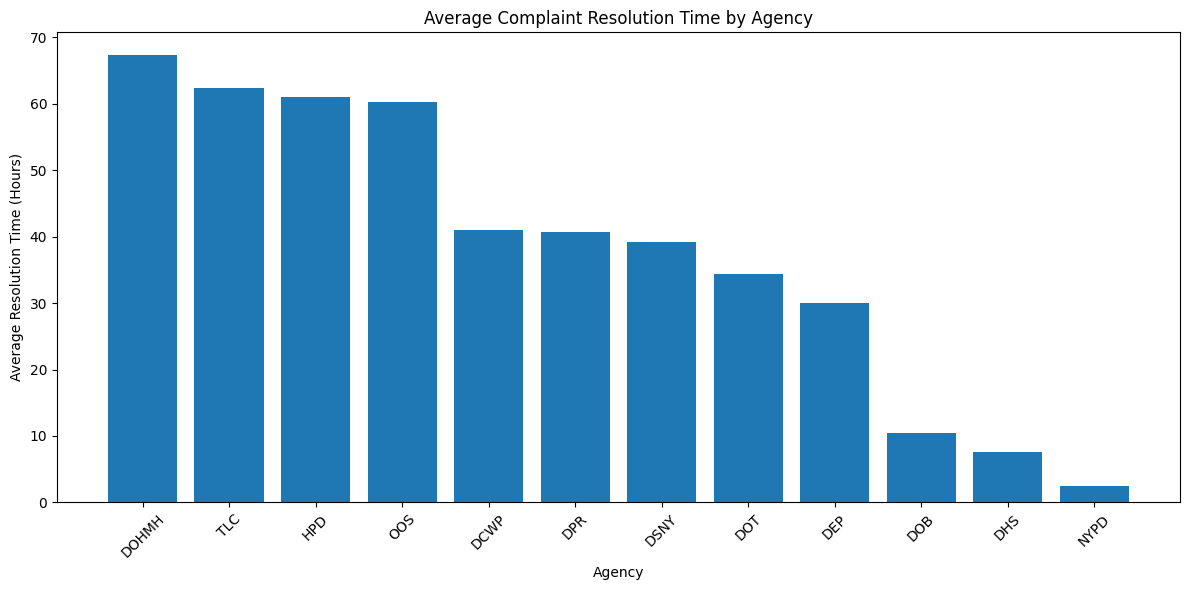

In [ ]:
plt.figure(figsize=(12, 6))

plt.bar(
    agency_df['Agency'],
    agency_df['Average_Hours']
)

plt.title('Average Complaint Resolution Time by Agency')
plt.xlabel('Agency')
plt.ylabel('Average Resolution Time (Hours)')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

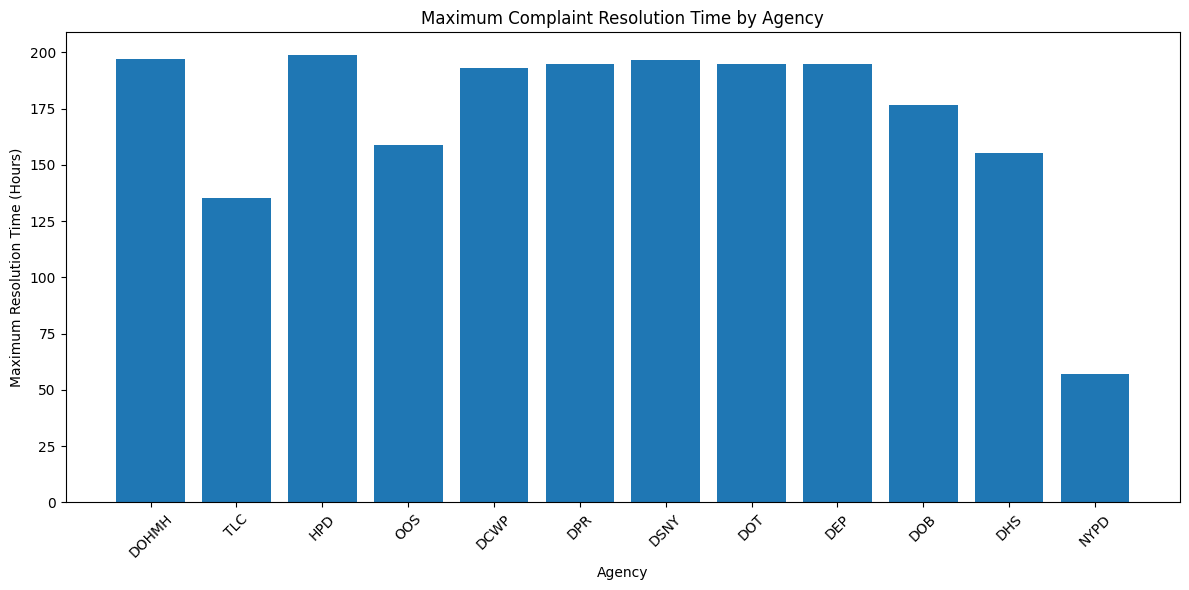

In [ ]:
plt.figure(figsize=(12, 6))

plt.bar(
    agency_df['Agency'],
    agency_df['Maximum_Hours']
)

plt.title('Maximum Complaint Resolution Time by Agency')
plt.xlabel('Agency')
plt.ylabel('Maximum Resolution Time (Hours)')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

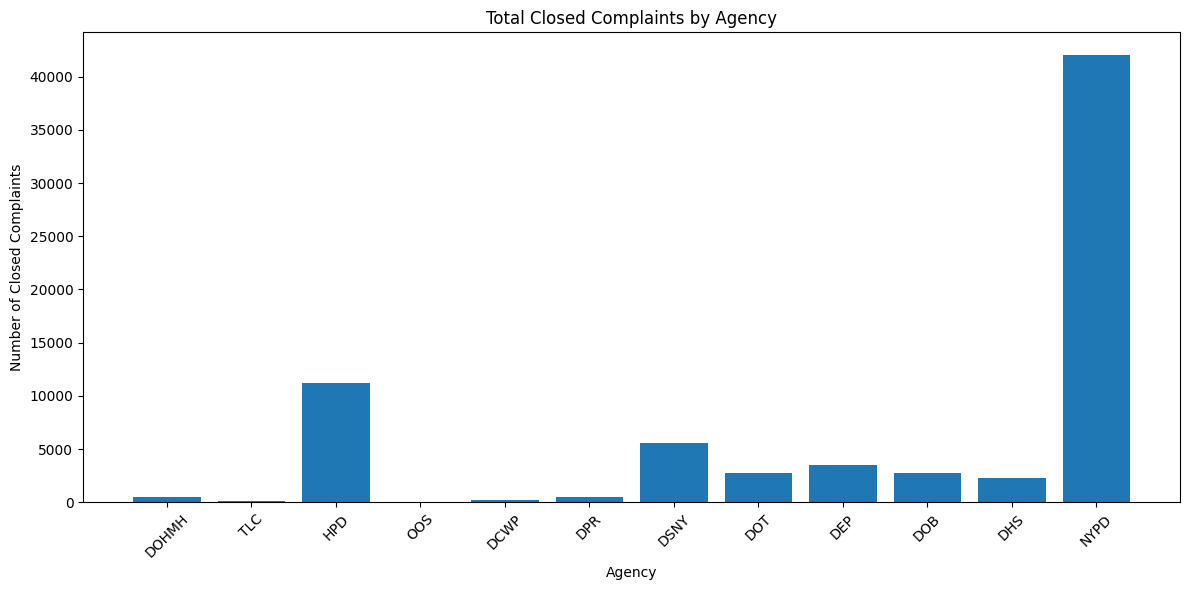

In [ ]:
plt.figure(figsize=(12, 6))

plt.bar(
    agency_df['Agency'],
    agency_df['Total_Records']
)

plt.title('Total Closed Complaints by Agency')
plt.xlabel('Agency')
plt.ylabel('Number of Closed Complaints')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
# Total service requests
total_requests = len(nyc311_df)

# Closed requests
closed_requests = nyc311_df['closed_date'].notna().sum()

# Open requests
open_requests = nyc311_df['closed_date'].isna().sum()

# Closure percentage
closure_rate = (closed_requests / total_requests) * 100

# Valid resolution records
resolution_data = nyc311_df[
    nyc311_df['closed_date'].notna()
].copy()

resolution_data['resolution_hours'] = (
    resolution_data['closed_date'] -
    resolution_data['created_date']
).dt.total_seconds() / 3600

resolution_data = resolution_data[
    resolution_data['resolution_hours'] >= 0
]

# Median resolution time
median_resolution = resolution_data[
    'resolution_hours'
].median()

# Average resolution time
average_resolution = resolution_data[
    'resolution_hours'
].mean()

# Requests taking more than 72 hours
delayed_requests = (
    resolution_data['resolution_hours'] > 72
).sum()

delayed_percentage = (
    delayed_requests / len(resolution_data)
) * 100

# Display KPIs
print("========== URBAN PULSE DASHBOARD KPIs ==========")

print("Total Requests:", total_requests)
print("Closed Requests:", closed_requests)
print("Open Requests:", open_requests)

print("Closure Rate:", round(closure_rate, 2), "%")

print("Average Resolution Time:",
      round(average_resolution, 2), "hours")

print("Median Resolution Time:",
      round(median_resolution, 2), "hours")

print("Requests Above 72 Hours:", delayed_requests)

print("Delayed Requests Percentage:",
      round(delayed_percentage, 2), "%")

========== URBAN PULSE DASHBOARD KPIs ==========
Total Requests: 99992
Closed Requests: 71583
Open Requests: 28409
Closure Rate: 71.59 %
Average Resolution Time: 18.51 hours
Median Resolution Time: 2.62 hours
Requests Above 72 Hours: 6820
Delayed Requests Percentage: 9.54 %


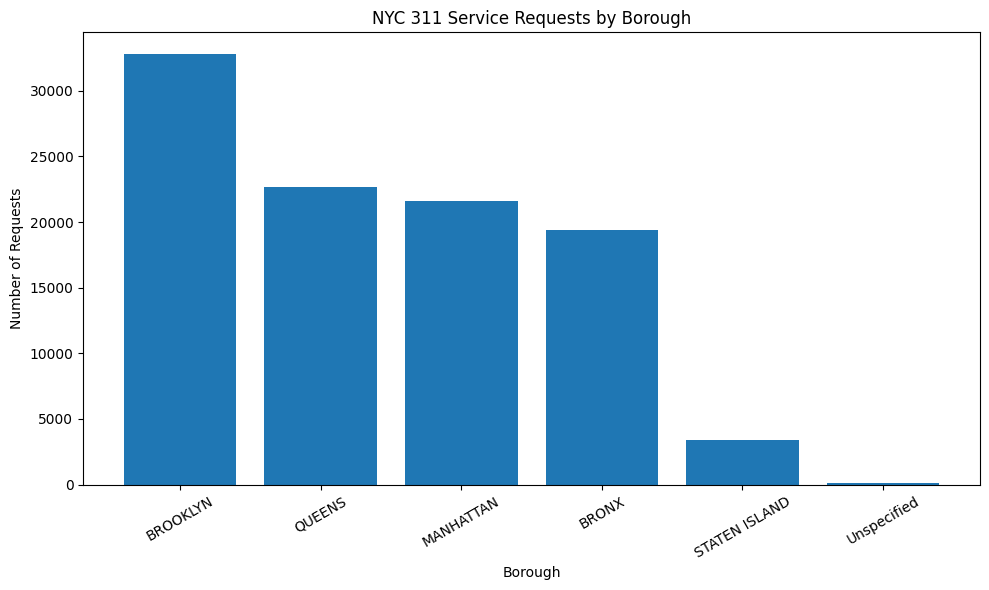

borough
BROOKLYN         32806
QUEENS           22674
MANHATTAN        21585
BRONX            19400
STATEN ISLAND     3413
Unspecified        114
Name: count, dtype: int64


In [ ]:
import matplotlib.pyplot as plt

# Count complaints by borough
borough_counts = (
    nyc311_df['borough']
    .fillna('Unspecified')
    .value_counts()
)

# Create chart
plt.figure(figsize=(10, 6))

plt.bar(
    borough_counts.index,
    borough_counts.values
)

plt.title('NYC 311 Service Requests by Borough')
plt.xlabel('Borough')
plt.ylabel('Number of Requests')

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Display exact counts
print(borough_counts)

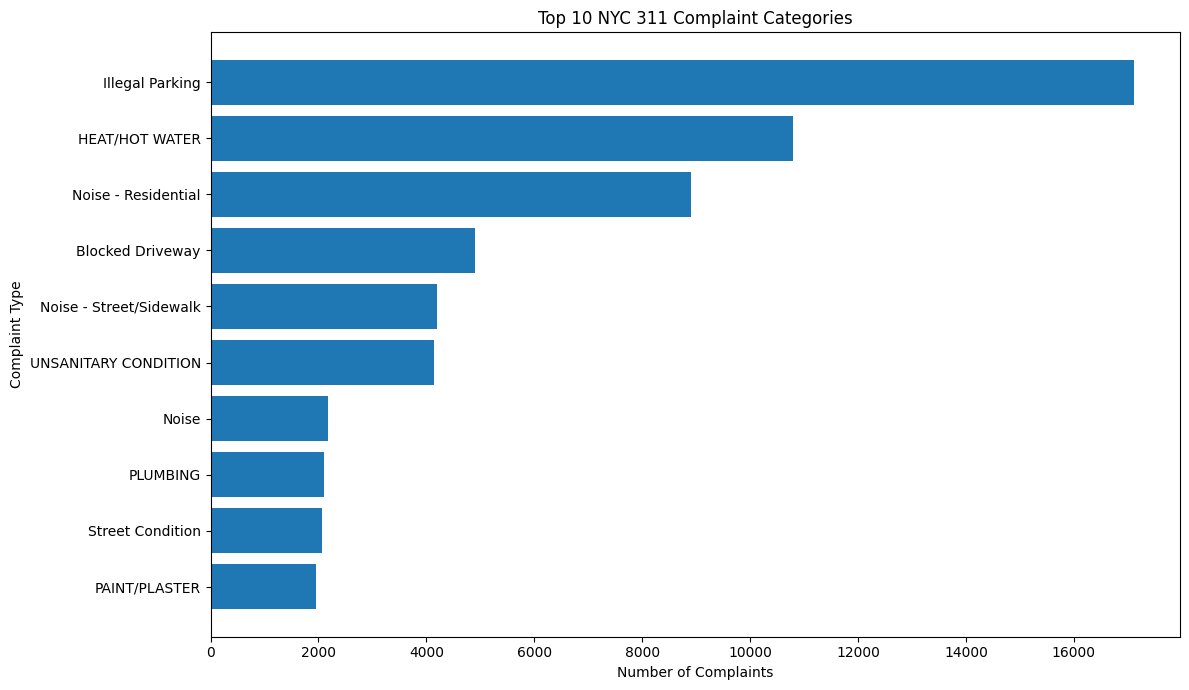

complaint_type
Illegal Parking            17112
HEAT/HOT WATER             10797
Noise - Residential         8906
Blocked Driveway            4902
Noise - Street/Sidewalk     4198
UNSANITARY CONDITION        4135
Noise                       2169
PLUMBING                    2112
Street Condition            2060
PAINT/PLASTER               1947
Name: count, dtype: int64


In [ ]:
import matplotlib.pyplot as plt

# Find the top 10 complaint categories
top_complaints = (
    nyc311_df['complaint_type']
    .value_counts()
    .head(10)
    .sort_values(ascending=True)
)

# Create horizontal bar chart
plt.figure(figsize=(12, 7))

plt.barh(
    top_complaints.index,
    top_complaints.values
)

plt.title('Top 10 NYC 311 Complaint Categories')
plt.xlabel('Number of Complaints')
plt.ylabel('Complaint Type')

plt.tight_layout()
plt.show()

# Display values
print(top_complaints.sort_values(ascending=False))

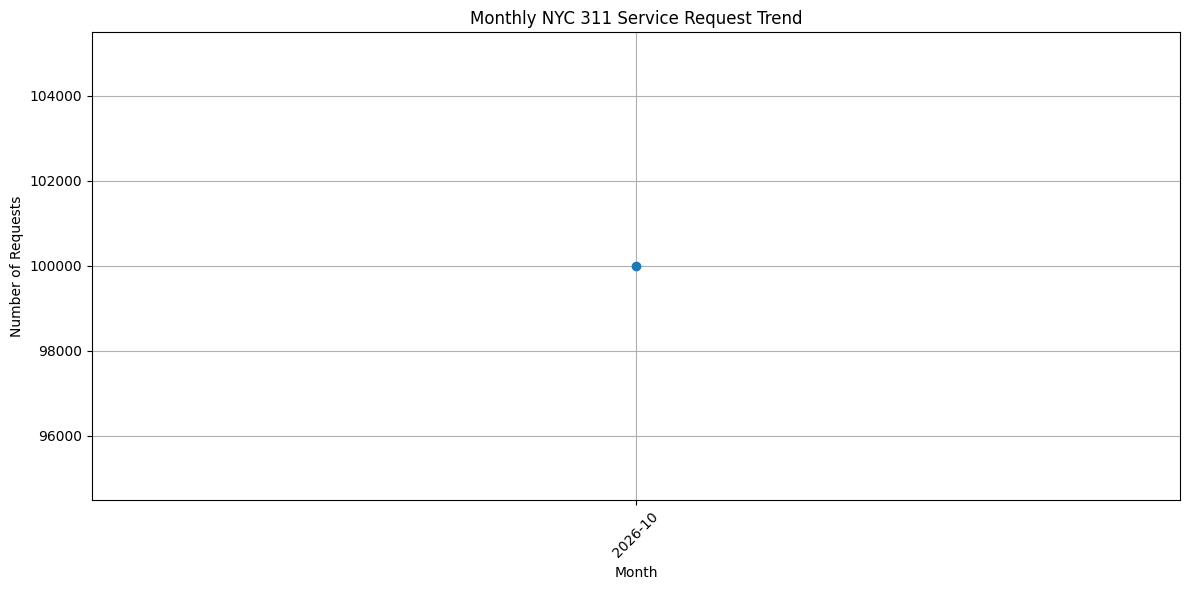

request_month
2026-10    99992
Freq: M, Name: unique_key, dtype: int64


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract month from created_date
nyc311_df['request_month'] = (
    nyc311_df['created_date'].dt.to_period('M')
)

# Count monthly complaints
monthly_requests = (
    nyc311_df.groupby('request_month')['unique_key']
    .nunique()
    .sort_index()
)

# Create line chart
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_requests.index.astype(str),
    monthly_requests.values,
    marker='o'
)

plt.title('Monthly NYC 311 Service Request Trend')
plt.xlabel('Month')
plt.ylabel('Number of Requests')

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

print(monthly_requests)

In [ ]:
# Save cleaned dataset for Streamlit dashboard

dashboard_df = nyc311_df.copy()

# Remove the temporary monthly analysis column
if 'request_month' in dashboard_df.columns:
    dashboard_df = dashboard_df.drop(
        columns=['request_month']
    )

# Export CSV
dashboard_df.to_csv(
    'urbanpulse_dashboard_data.csv',
    index=False
)

print("Dashboard dataset saved successfully!")
print("Total records:", len(dashboard_df))
print("Total columns:", len(dashboard_df.columns))

Dashboard dataset saved successfully!
Total records: 99992
Total columns: 10


In [ ]:
from google.colab import files

files.download('urbanpulse_dashboard_data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>